# Active Subspaces of a Coupled Hall Thruster Model: Thrust and Discharge Current of the SPT-100

__Thomas A. Marks__, __Joshua D. Eckels__, __Gabriel E. Mora__ and __Alex A. Gorodetsky__, Department of Aerospace Engineering, University of Michigan, Ann Arbor, Michigan, USA

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

**Summary.** Marks et al. [[1]](https://doi.org/10.1063/5.0283796) couple a cathode-coupling model, the 1-D fluid discharge code HallThruster.jl and a semi-empirical plume model, calibrate them against Hall thruster data taken at many facility pressures by Bayesian inference, and compute Sobol' indices of the outputs over the prior of 18 model parameters. Here the coupled model was run 440 times on a Latin hypercube over that prior for the SPT-100 at one of the paper's training conditions (300 V, 12.3 µTorr-Xe), and active subspaces of the corrected thrust and the discharge current are estimated with the global quadratic estimator from the 420 runs whose discharge does not oscillate (all 440 runs as a sensitivity check). The corrected thrust depends mainly on one direction, dominated by the plume's zero-pressure divergence angle $c_3$ ($\lambda_1/\lambda_2\approx$ 18, about 11 with all runs; both still rise with the number of runs), and the discharge current on a two-dimensional subspace of the anomalous-transport scale $\alpha_{anom}$ and barrier depth $\beta_{anom}$ ($\lambda_2/\lambda_3\approx$ 10).

It runs in Python 3 with numpy, scipy, matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, in under a minute. It does not run the simulator; `DATA.md` says how the data were generated with HallThruster.jl and how to rerun it.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ inputs with density $\rho$ on the normalized domain $[-1,1]^m$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T\rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. A large gap after the $n$-th eigenvalue means that $f$ changes mostly along the $n$ directions $\mathbf W_1$, so $f(\mathbf x)\approx g(\mathbf W_1^T\mathbf x)$, and a *sufficient summary plot* of $f$ against the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ shows the structure. Without gradients, $\mathbf C$ can be approximated by fitting a global quadratic $q(\mathbf x)$ to samples of $f$ by least squares and averaging $\nabla q\,\nabla q^T$ instead. See Constantine (2015) [[2]](https://doi.org/10.1137/1.9781611973860).

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac

SEED = 662                        # the only seed in this notebook (bootstrap)
t_start = time.perf_counter()
warnings.filterwarnings('ignore', category=ac.ValidityWarning)   # QPHD on a uniform space; see below
warnings.formatwarning = lambda msg, cat, *args, **kw: f'{cat.__name__}: {msg}\n'   # no temp-file paths in outputs

NAMES = ['Tec', 'Vvac', 'PT', 'Pstar', 'alpha_anom', 'beta_anom', 'z_anom', 'L_anom', 'dz_anom',
         'u_n', 'c_w', 'f_n', 'c0', 'c1', 'c2', 'c3', 'log10_c4', 'log10_c5']
LABELS = [r'$T_{ec}$', r'$V_{vac}$', r'$P_T$', r'$P^*$', r'$\alpha_{anom}$', r'$\beta_{anom}$',
          r'$z_{anom}$', r'$L_{anom}$', r'$\Delta z_{anom}$', r'$u_n$', r'$c_w$', r'$f_n$',
          r'$c_0$', r'$c_1$', r'$c_2$', r'$c_3$', r'$\log_{10}c_4$', r'$\log_{10}c_5$']
# Table I of the paper; c4 and c5 are log-uniform, so their bounds are bounds of the exponent
LOWER = np.array([1.0, 0.0, 20.0, 1.0, 0.0, 0.0, 0.75, 0.0, 0.0, 100.0, 0.5, 1.0,
                  0.0, 0.1, -15.0, 0.2, 18.0, 14.0])
UPPER = np.array([6.0, 60.0, 200.0, 100.0, 1.0, 1.0, 1.5, 0.5, 0.5, 500.0, 1.5, 10.0,
                  1.0, 0.9, 15.0, np.pi / 2, 22.0, 18.0])
UNITS = ['eV', 'V', 'µTorr', 'µTorr', '-', '-', 'L_ch', 'L_ch', 'L_ch', 'm/s', '-', '-', '-', '-',
         'rad/Pa', 'rad', 'log10(m^-3/Pa)', 'log10(m^-3)']
COMPONENT = ['cathode'] * 4 + ['thruster'] * 8 + ['plume'] * 6
DESCR = ['cathode electron temperature', 'vacuum coupling voltage', 'base pressure',
         'turning-point pressure', 'base inverse Hall parameter', 'transport barrier depth',
         'transport barrier location', 'transport barrier width', 'pressure shift scale',
         'neutral axial speed', 'electron wall-loss scale', 'neutral ingestion scale',
         'scattered / total beam current', 'main / scattered divergence angle',
         'divergence angle slope vs P_B', 'divergence angle at P_B = 0',
         'neutral density slope vs P_B', 'neutral density at P_B = 0']
space = ac.Uniform(LOWER, UPPER, names=NAMES)
m = len(NAMES)

### The model

The coupled model of Marks et al. [[1]](https://doi.org/10.1063/5.0283796) (their Fig. 1) chains three components; each depends on the facility background pressure $P_B$.

**Cathode coupling** (Jorns and Byrne [[4]](https://doi.org/10.1088/1361-6595/abd3b6); paper Eq. (2)) gives the voltage needed to draw cathode electrons into the discharge,

$$V_{cc} = V_{vac} + T_{ec}\ln\!\left(1+\frac{P_B}{P_T}\right) - \frac{T_{ec}}{P_T+P^*}\,P_B .$$

**Thruster discharge.** HallThruster.jl [[3]](https://doi.org/10.21105/joss.04672), version 0.18.7, solves the 1-D axial quasineutral equations: neutral continuity, ion continuity and momentum (singly-charged xenon only), and an electron energy equation, with the electrons an inertialess fluid whose current follows the generalized Ohm's law. $V_{cc}$ sets the cathode-boundary potential. The anomalous cross-field transport is prescribed (paper Eq. (3)) as an inverse Hall parameter that is Bohm-like with a Gaussian barrier,

$$\Omega_{anom}^{-1} = \alpha_{anom}\left(1-\beta_{anom}\exp\left[-\left(\frac{\hat z - z_{anom}}{L_{anom}}\right)^2\right]\right),$$

with $\hat z$ the axial coordinate in channel lengths, shifted upstream with pressure by (Eq. (4))

$$\Delta z(P_B) = \Delta z_{anom}L_{ch}\left(\frac{1}{1+e^{-2(P_B/P_0-1)}}-\frac{1}{1+e^{2}}\right),\qquad P_0 = 25\ \mu\text{Torr}.$$

HallThruster.jl's `ScaledGaussianBohm` model, which the authors' code uses, writes the barrier as $\exp[-\tfrac12((\hat z-z_{anom})/L_{anom})^2]$, so $L_{anom}$ is a standard deviation; the runs here pass $L_{anom}$ to it unchanged (see `DATA.md`). The neutral flux ingested from the facility is multiplied by $f_n$, and the electron wall-loss model's edge-to-centre density ratio (about 0.5) by $c_w$. Grid: 100 cells over three channel lengths; 1 ms simulated, every output averaged over the last 500 µs. The SPT-100 geometry and magnetic field are those of the authors' HallThrusterPEM package.

**Plume** (paper Refs. 10 and 13 [[5]](https://doi.org/10.1007/s44205-024-00079-w); Eqs. (5)–(7)). The ion current density at distance $r$ and angle $\phi$ from the centreline is a main beam and a scattered population with Gaussian angular profiles, of divergence $\alpha_1 = c_2P_B + c_3$ and $\alpha_2 = \alpha_1/c_1$ and current fractions $1-c_0$ and $c_0$, plus charge-exchange ions spread over the hemisphere, whose fraction $1-e^{-r n\sigma_{cex}}$ grows with the neutral density $n = c_4P_B + c_5$. The divergence angle $\phi_d$ comes from the axial and total currents of the beam and scattered ions, charge-exchange ions excluded (Eq. (6) as corrected in the erratum to the paper), and corrects the thrust, $T_c = T\cos\phi_d$ (Eq. (7)).

**Operating condition, held fixed.** The paper calibrates with the operating conditions at their nominal values. All runs here use one SPT-100 condition from its training data (Diamant et al. [[6]](https://doi.org/10.2514/6.2014-3710), L3 facility, condition 4): discharge voltage 300 V, background pressure 12.3 µTorr-Xe, total flow 5.665 mg/s with anode-to-cathode ratio 12, so anode flow 5.229 mg/s. At this $P_B$ = 1.64 × 10⁻³ Pa, $c_2P_B$ changes $\alpha_1$ by at most ±0.025 rad, so $c_2$ can matter little here.

**Quantities of interest.** The corrected thrust $T_c$ (mN) and the discharge current $I_D$ (A), the two performance outputs in the paper's training and test data (its Table III). The file also holds $V_{cc}$, the ion current $I_B$, the uncorrected thrust $T$, the exit-plane ion velocity and the peak plume current density, used in the comparison with the paper at the end.

**Inputs.** The 18 model parameters of the paper's Table I, independent and uniform; $c_4$ and $c_5$ are log-uniform, so the analysis uses their base-10 logarithms, which are uniform. The table is printed from the bounds in the code cell above. Two caveats. (i) The paper is not consistent about the cathode pressures: Table I gives $P_T\sim U(20, 200)$ and $P^*\sim U(1, 100)$ µTorr, but Table IV (p. 9), the SPT-100 posterior, lists the prior as $P_T\sim U(10, 100)$ and $P^*\sim U(10, 200)$, and its posterior samples reach $P_T$ = 10 and $P^*$ = 197.95, outside Table I's box; so the paper's SPT-100 runs used Table IV's ranges (as does the authors' configuration file), not Table I's. Table I is kept here because it is the paper's stated prior and the design was drawn from it; at this background pressure $P_T$ and $P^*$ carry almost no activity for either QoI (see the comparison below), so the choice changes neither subspace. (ii) Table I calls $c_0$ the "ratio of main to scattered currents", but the plume model (paper Eq. (5) and the authors' code) uses $c_0$ as the scattered fraction of the beam current, as here.

In [2]:
print(f"{'name':>11}  {'component':>9}  {'lower':>7}  {'upper':>7}  {'units':>15}  description")
for i in range(m):
    print(f"{NAMES[i]:>11}  {COMPONENT[i]:>9}  {LOWER[i]:7.3g}  {UPPER[i]:7.3g}  {UNITS[i]:>15}  {DESCR[i]}")

       name  component    lower    upper            units  description
        Tec    cathode        1        6               eV  cathode electron temperature
       Vvac    cathode        0       60                V  vacuum coupling voltage
         PT    cathode       20      200            µTorr  base pressure
      Pstar    cathode        1      100            µTorr  turning-point pressure
 alpha_anom   thruster        0        1                -  base inverse Hall parameter
  beta_anom   thruster        0        1                -  transport barrier depth
     z_anom   thruster     0.75      1.5             L_ch  transport barrier location
     L_anom   thruster        0      0.5             L_ch  transport barrier width
    dz_anom   thruster        0      0.5             L_ch  pressure shift scale
        u_n   thruster      100      500              m/s  neutral axial speed
        c_w   thruster      0.5      1.5                -  electron wall-loss scale
        f_n   thruste

### Load the data

`hall_thruster_spt100.csv` holds a 440-point Latin hypercube over the 18 inputs (seed 662) and the outputs of the coupled model, one row per run, with `NaN` outputs where HallThruster.jl failed. Inputs are in physical units, $c_4$ and $c_5$ as values, not exponents. The last column, `oscillating`, flags runs whose discharge current oscillates over the averaging window (rule below); no run is removed from the file.

In [3]:
FILE = 'hall_thruster_spt100.csv'
data = np.loadtxt(FILE, delimiter=',')
with open(FILE) as fh:
    fh.readline()
    cols = [c.split(' [')[0] for c in fh.readline().lstrip('# ').strip().split(', ')]
col = {c: data[:, i] for i, c in enumerate(cols)}
X_phys = data[:, :m]
status = col['status'].astype(int)
oscillating = col['oscillating'] == 1        # flag stored in the file: std/mean of I_D(t) > 1 %
print('data', data.shape, '; inputs', X_phys.shape, '; output columns', cols[m:])
print('runs by status (0 ok, 1 solver retcode, 2 exception, 3 non-finite):', np.bincount(status, minlength=4))
PB_Pa = 12.3e-6 * 101325 / 760
print(f'operating P_B = {PB_Pa:.3g} Pa, so |c2 P_B| <= {15 * PB_Pa:.3f} rad over the c2 range')

data (440, 35) ; inputs (440, 18) ; output columns ['status', 'Vcc', 'ID', 'IB', 'T', 'Tc', 'u_exit', 'j_peak', 'phi_d', 'ID_std', 'T_std', 'ID_a', 'ID_b', 'T_a', 'T_b', 'wall_s', 'oscillating']
runs by status (0 ok, 1 solver retcode, 2 exception, 3 non-finite): [440   0   0   0]
operating P_B = 0.00164 Pa, so |c2 P_B| <= 0.025 rad over the c2 range


The one change of coordinates in this notebook: $c_4$ and $c_5$ are replaced by their base-10 logarithms, the coordinates in which Table I's distributions are uniform. Every input is then mapped to $[-1,1]$ by its own range (inside `ac.Uniform`), so all 18 are scaled the same way.

Two row rules, both stated here and used throughout. **All runs**: `status == 0` (the run finished). **Steady runs**: `status == 0` and `oscillating == 0`, where a run is *oscillating* if the standard deviation of $I_D(t)$ over the 500 µs averaging window exceeds 1 % of its mean (the file's `ID_std / ID > 0.01`; the next section shows why). The steady runs give the main results; all runs are a sensitivity check.

In [4]:
X_all = X_phys.copy()
X_all[:, 16:18] = np.log10(X_phys[:, 16:18])
ok = status == 0
X = X_all[ok]                     # all finished runs
Tc = 1e3 * col['Tc'][ok]          # mN
ID = col['ID'][ok]                # A
osc = oscillating[ok]
st = ~osc                         # steady runs (main analysis)
M, M_st = X.shape[0], int(st.sum())
Xn = space.to_normalized(X)
strata = [np.unique(np.floor((space.to_normalized(X_all)[:, j] + 1) / 2 * len(X_all))).size for j in range(m)]
print(f'{M} of {len(X_all)} runs finished; {M_st} steady, {M - M_st} oscillating; '
      f'quadratic coefficients (m+1)(m+2)/2 = {(m + 1) * (m + 2) // 2}')
print('inside the box:', bool(np.all((Xn >= -1) & (Xn <= 1))), '; LHS strata filled per input (min over inputs):', min(strata))
print('Vcc range [V]: %.2f to %.2f' % (np.nanmin(col['Vcc']), np.nanmax(col['Vcc'])))
for name, f, u in [('Tc', Tc, 'mN'), ('ID', ID, 'A')]:
    print(f'{name} [{u}]: min {f.min():.3f}, median {np.median(f):.3f}, max {f.max():.3f}')

440 of 440 runs finished; 420 steady, 20 oscillating; quadratic coefficients (m+1)(m+2)/2 = 190
inside the box: True ; LHS strata filled per input (min over inputs): 440
Vcc range [V]: 0.20 to 60.01
Tc [mN]: min 20.872, median 57.094, max 99.422
ID [A]: min 2.928, median 40.045, max 69.250


All 440 runs finished (none failed), each of the 440 Latin hypercube strata of every input holds one sample, and every input lies in its box. The prior is wide: the median discharge current is 40.0 A, against 4.5 A measured at this condition, because $\alpha_{anom}$ up to 1 allows up to 16 times Bohm transport (Bohm is $\Omega^{-1} = 1/16$). The analysis therefore describes the model over the paper's prior, as its Sobol' analysis does, not the calibrated thruster (`DATA.md` gives the counts of runs near the measurements).

**Time averages are not exact.** HallThruster.jl's discharges can oscillate (the breathing mode), and each output is an average over 500 µs. The file also holds the averages over the first and second halves of that window; their difference measures how far the 500 µs average is from a converged one. The cell also checks the oscillation rule: how many runs other thresholds would flag, whether the half-window criteria pick out other runs, and where the flagged runs lie in $\alpha_{anom}$.

In [5]:
rel = {}
for q in ['ID', 'T']:
    rel[q] = np.abs(col[q + '_a'] - col[q + '_b'])[ok] / np.abs(col[q][ok])
    p50, p90, p99 = np.percentile(rel[q], [50, 90, 99])
    print(f'{q}: |first half - second half| / mean: median {p50:.1e}, 90th pct {p90:.1e}, 99th pct {p99:.1e}, '
          f'max {rel[q].max():.2f}; runs above 1 %: {np.sum(rel[q] > 0.01)}')
r_osc = col['ID_std'][ok] / ID
print('runs flagged with threshold std/mean of I_D(t) > 0.5 %, 1 %, 2 %:',
      [int(np.sum(r_osc > t)) for t in (0.005, 0.01, 0.02)], '; the file flag (1 %):', int(osc.sum()))
half = (rel['ID'] > 0.01) | (rel['T'] > 0.01)
print(f'runs whose half-window averages of I_D or T differ by > 1 %: {half.sum()}, of them flagged: {np.sum(half & osc)}')
a_osc = X[osc, 4]
print(f'alpha_anom of the oscillating runs: max {a_osc.max():.3f}; {np.sum(a_osc < 0.06)} of the '
      f'{np.sum(X[:, 4] < 0.06)} runs with alpha_anom < 0.06 (the SPT-100 posterior median, Table IV) oscillate')

ID: |first half - second half| / mean: median 1.6e-11, 90th pct 1.1e-04, 99th pct 8.9e-02, max 0.63; runs above 1 %: 13
T: |first half - second half| / mean: median 1.2e-11, 90th pct 7.7e-05, 99th pct 1.1e-01, max 0.48; runs above 1 %: 15
runs flagged with threshold std/mean of I_D(t) > 0.5 %, 1 %, 2 %: [29, 20, 18] ; the file flag (1 %): 20
runs whose half-window averages of I_D or T differ by > 1 %: 16, of them flagged: 16
alpha_anom of the oscillating runs: max 0.261; 17 of the 26 runs with alpha_anom < 0.06 (the SPT-100 posterior median, Table IV) oscillate


Most runs reach a steady state: the median difference between the half-window averages is about $10^{-11}$. In 20 runs the discharge current oscillates by more than 1 % (standard deviation over mean); these are the runs flagged in the file's `oscillating` column. The rule is not sensitive to the threshold (29 runs at 0.5 %, 18 at 2 %), and it catches every run whose two half-window averages of $I_D$ or $T$ differ by more than 1 % (16 runs, by up to 63 % and 48 %). That error is noise in $f$ that no smooth function of the inputs can fit: rerunning one oscillating run for 2 ms changed its thrust by 11 % (`DATA.md`, Accuracy; a rerun outside this notebook, which `check_accuracy.py` repeats where HallThruster.jl is installed). So the main analysis uses the 420 steady runs, and the oscillating runs are kept in the file, marked in the plots and used in the sensitivity rows.

**Caution: the oscillating runs sit where the calibrated thruster is.** They are low-transport runs: the largest $\alpha_{anom}$ among them is 0.261, and 17 of the 26 runs with $\alpha_{anom}$ below 0.06, the paper's SPT-100 posterior median (Table IV), oscillate. Their thrust carries about 10 % averaging error, so the data, and any surrogate built from them, are least reliable near the measured operating point. The subspaces below describe the model over the prior, away from that corner.

### Estimate the active subspaces

There are no gradients, and finite differences of 500 µs averages of an oscillating discharge would be dominated by the averaging error just measured. So the subspaces are estimated from values with the global quadratic estimator (QPHD): a full quadratic in the 18 normalized inputs (190 coefficients) is fitted by least squares to the runs, and $\mathbf C = \mathbf g\mathbf g^T + \mathbf H\Sigma\mathbf H$ is the average of $\nabla q\nabla q^T$ over the uniform density, with $\Sigma = \tfrac13\mathbf I$ its covariance (Li [[7]](https://doi.org/10.1080/01621459.1992.10476258)). (The library warns that QPHD's justification is for Gaussian inputs; with the uniform covariance used here, $\mathbf C$ is still exactly the average gradient outer product of the fitted quadratic, so the warning is silenced in the first cell.) The eigenvalues therefore describe the quadratic $q$, not $f$ itself: they are trustworthy where $q$ fits well, which the in-sample and leave-one-out $R^2$ of $q$ check. The bootstrap (500 replicates, seed 662) resamples the runs; a replicate holds about 63 % distinct runs, about 265 of the 420 steady runs for 190 coefficients. The eigenvalue *ratios* depend on the number of runs: with few runs per coefficient the least-squares quadratic partly fits noise, which inflates the trailing eigenvalues and lowers the ratios. The bootstrap intervals of the ratios therefore lie low, and a separate check below (subsamples of increasing size) shows how far the ratios have converged; they are quoted as approximate. Two further checks of the first direction: the direction of an ordinary least-squares linear fit, and QPHD on each half of the runs. The eigenvalue-gap rule (`evg`) and the largest-ratio rule over the bootstrap replicates are printed, but the dimension is chosen from the ratios, the subspace errors and the surrogates below (stated after the results); signs are set so that $f$ increases with each active variable.

The main analysis uses the 420 steady runs; the next cell repeats it on all 440 runs as a sensitivity check.

In [6]:
def quad_design(Z):
    ju, ku = np.triu_indices(Z.shape[1], k=1)
    return np.column_stack([np.ones(len(Z)), Z, Z**2, Z[:, ju] * Z[:, ku]])

def r2_quadratic(f, rows=None):
    rows = np.ones(len(f), bool) if rows is None else rows
    A = quad_design(Xn[rows])
    f = f[rows]
    coef, *_ = np.linalg.lstsq(A, f, rcond=None)
    res = f - A @ coef
    h = np.einsum('ij,ji->i', A, np.linalg.pinv(A))
    ss = np.sum((f - f.mean())**2)
    return 1 - res @ res / ss, 1 - np.sum((res / (1 - h))**2) / ss

def ratio_ci(boot, k):
    return ac.bootstrap_interval(boot[:, k] / boot[:, k + 1])[:, 0]

def estimate(f, qoi, n, rows, label, verbose=True):
    Xr, fr = X[rows], f[rows]
    sub = ac.active_subspace(space=space, X=Xr, f=fr, estimator='qphd', nboot=500, bootstrap_vectors=2,
                             rng=SEED, qoi=qoi)
    sub = ac.orient(sub, by='covariance', X=Xr, f=fr, columns=2)
    lam, boot = sub.eigenvalues, sub.bootstrap_eigenvalues
    r12, r23 = ratio_ci(boot, 0), ratio_ci(boot, 1)
    r2_in, r2_loo = r2_quadratic(f, rows)
    largest = np.argmax(boot[:, :8] / boot[:, 1:9], axis=1) + 1          # largest-ratio rule per replicate
    print(f'{qoi}, {label} ({rows.sum()} runs): quadratic fit R^2 in-sample {r2_in:.3f}, leave-one-out {r2_loo:.3f}')
    print('  eigenvalues 1-6:', np.array2string(lam[:6], precision=3))
    print(f'  lambda1/lambda2 = {lam[0] / lam[1]:.1f} (bootstrap 95 %: {r12[0]:.1f} to {r12[1]:.1f}), '
          f'lambda2/lambda3 = {lam[1] / lam[2]:.1f} (bootstrap 95 %: {r23[0]:.1f} to {r23[1]:.1f})')
    print(f'  lambda1 / trace = {lam[0] / lam.sum():.3f}, (lambda1 + lambda2) / trace = {lam[:2].sum() / lam.sum():.3f}; '
          f'largest-ratio rule over 500 replicates picks n = 1: {np.sum(largest == 1)}, n = 2: {np.sum(largest == 2)}')
    if verbose:
        w_ols = ac.active_subspace(space=space, X=Xr, f=fr, estimator='ols', n=1).W1[:, 0]
        idx = np.where(rows)[0]
        perm = np.random.default_rng(SEED).permutation(idx)
        hlf = len(idx) // 2
        halves = [ac.active_subspace(space=space, X=X[h], f=f[h], estimator='qphd', n=1).W1[:, 0]
                  for h in (perm[:hlf], perm[hlf:])]
        _, _, n_evg = ac.dimension_criterion(sub, rule='evg')
        print(f'  dimension by the eigenvalue-gap rule: {n_evg}; subspace errors k = 1, 2, 3:',
              np.array2string(sub.bootstrap_distances.mean(axis=0)[:3], precision=3))
        print(f'  |w1 . w_ols| = {abs(sub.W[:, 0] @ w_ols):.3f}; |w1 . w1(half)| = '
              f'{abs(sub.W[:, 0] @ halves[0]):.3f}, {abs(sub.W[:, 0] @ halves[1]):.3f}')
    return ac.with_dimension(sub, n)

sub_T = estimate(Tc, 'Tc', 1, st, 'steady runs')
sub_I = estimate(ID, 'ID', 2, st, 'steady runs')

Tc, steady runs (420 runs): quadratic fit R^2 in-sample 0.984, leave-one-out 0.939
  eigenvalues 1-6: [475.032  26.778  18.75    8.231   7.945   4.901]
  lambda1/lambda2 = 17.7 (bootstrap 95 %: 8.7 to 18.8), lambda2/lambda3 = 1.4 (bootstrap 95 %: 1.1 to 2.2)
  lambda1 / trace = 0.859, (lambda1 + lambda2) / trace = 0.908; largest-ratio rule over 500 replicates picks n = 1: 500, n = 2: 0
  dimension by the eigenvalue-gap rule: 1; subspace errors k = 1, 2, 3: [0.078 0.547 0.606]
  |w1 . w_ols| = 0.997; |w1 . w1(half)| = 0.980, 0.986


ID, steady runs (420 runs): quadratic fit R^2 in-sample 0.983, leave-one-out 0.936
  eigenvalues 1-6: [900.032 217.009  21.323  13.922   6.94    5.112]
  lambda1/lambda2 = 4.1 (bootstrap 95 %: 3.0 to 5.4), lambda2/lambda3 = 10.2 (bootstrap 95 %: 3.5 to 9.9)
  lambda1 / trace = 0.763, (lambda1 + lambda2) / trace = 0.947; largest-ratio rule over 500 replicates picks n = 1: 60, n = 2: 440
  dimension by the eigenvalue-gap rule: 1; subspace errors k = 1, 2, 3: [0.078 0.176 0.665]
  |w1 . w_ols| = 0.984; |w1 . w1(half)| = 0.978, 0.986


**$T_c$ (steady runs).** Without the oscillating runs the quadratic fits well (in-sample $R^2$ 0.984, leave-one-out 0.939). The first eigenvalue stands apart: $\lambda_1/\lambda_2$ = 17.7, and $\lambda_1$ is 0.859 of the trace; $\lambda_2/\lambda_3$ is only 1.4. The bootstrap interval for $\lambda_1/\lambda_2$, 8.7 to 18.8, lies mostly below the point value, because each replicate fits 190 coefficients to about 265 distinct runs (the convergence check below shows what that does to the ratio). What is robust: the largest-ratio rule picks $n$ = 1 in all 500 replicates, the subspace error for $k$ = 1 is 0.078, and the first direction agrees with the least-squares linear direction to $|w_1^Tw_{ols}|$ = 0.997 and with QPHD on each half of the runs to 0.980 and 0.986. The library's warning concerns $w_2$, whose replicates do not line up.

**$I_D$ (steady runs).** The quadratic fits with in-sample $R^2$ 0.983 and leave-one-out 0.936. $\lambda_1/\lambda_2$ = 4.1 (bootstrap 3.0 to 5.4) and $\lambda_2/\lambda_3$ = 10.2 (bootstrap 3.5 to 9.9, again below the point value); the first two eigenvalues make up 0.947 of the trace. The gap rule picks 1, but the largest-ratio rule picks 2 in 440 of 500 replicates, the subspace error for $k$ = 2 is small (0.176), and the two-variable surrogate below fits far better than the one-variable one, so $n$ = 2 for $I_D$ and $n$ = 1 for $T_c$. The first direction agrees with the linear direction to 0.984 and across halves to 0.978 and 0.986.

**Sensitivity: all 440 runs.** The same estimate with the oscillating runs included, and the distance between the two subspaces, $\|\mathbf W_1\mathbf W_1^T - \mathbf V_1\mathbf V_1^T\|_2$.

In [7]:
def dist(A, B):
    return np.linalg.norm(A @ A.T - B @ B.T, 2)

all_rows = np.ones(M, bool)
sub_T_all = estimate(Tc, 'Tc', 1, all_rows, 'all runs', verbose=False)
sub_I_all = estimate(ID, 'ID', 2, all_rows, 'all runs', verbose=False)
print(f'steady vs all runs: Tc |w1 . w1| = {abs(sub_T.W1[:, 0] @ sub_T_all.W1[:, 0]):.3f}; '
      f'ID distance between the 2-D subspaces = {dist(sub_I.W1, sub_I_all.W1):.3f}')

Tc, all runs (440 runs): quadratic fit R^2 in-sample 0.924, leave-one-out 0.754
  eigenvalues 1-6: [442.632  41.21   25.777  22.517  14.131   9.042]
  lambda1/lambda2 = 10.7 (bootstrap 95 %: 2.9 to 11.8), lambda2/lambda3 = 1.6 (bootstrap 95 %: 1.0 to 2.3)
  lambda1 / trace = 0.755, (lambda1 + lambda2) / trace = 0.826; largest-ratio rule over 500 replicates picks n = 1: 498, n = 2: 2


ID, all runs (440 runs): quadratic fit R^2 in-sample 0.983, leave-one-out 0.942
  eigenvalues 1-6: [890.617 218.004  17.052  11.153   6.532   4.897]
  lambda1/lambda2 = 4.1 (bootstrap 95 %: 3.0 to 5.4), lambda2/lambda3 = 12.8 (bootstrap 95 %: 4.5 to 11.4)
  lambda1 / trace = 0.766, (lambda1 + lambda2) / trace = 0.954; largest-ratio rule over 500 replicates picks n = 1: 18, n = 2: 482
steady vs all runs: Tc |w1 . w1| = 0.992; ID distance between the 2-D subspaces = 0.047


With the 20 oscillating runs included, the $T_c$ quadratic fits far worse (leave-one-out $R^2$ 0.754 against 0.939) and $\lambda_1/\lambda_2$ falls from 17.7 to 10.7 (bootstrap 2.9 to 11.8): the noise in those runs inflates $\lambda_2$ from 26.778 to 41.21. The direction hardly moves ($|w_1^Tw_1|$ = 0.992 between the two analyses), and $n$ = 1 is still chosen in 498 of 500 replicates. For $I_D$ the oscillating runs matter little: $\lambda_2/\lambda_3$ = 12.8 (bootstrap 4.5 to 11.4) against 10.2, and the two-dimensional subspaces differ by 0.047. So the dimensions and directions do not depend on the rule; the $T_c$ eigenvalue ratio does.

**Convergence in the number of runs.** QPHD on random subsets of 250, 300, 350 and 400 runs, drawn without replacement (50 subsets per size, seed 662), with the full set last. A ratio that still rises at the full set has not converged, and the value printed for the full set is then a lower estimate of what more runs would give. The eigenvalues are computed with the same quadratic fit in numpy (checked against the library on the full set) to keep the cell fast.

In [8]:
ju, ku = np.triu_indices(m, k=1)

def qphd_eigenvalues(Z, f):
    coef, *_ = np.linalg.lstsq(quad_design(Z), f, rcond=None)
    H = np.diag(2 * coef[m + 1:2 * m + 1])
    H[ju, ku] = H[ku, ju] = coef[2 * m + 1:]
    b = coef[1:m + 1]
    return np.linalg.eigvalsh(np.outer(b, b) + H @ H / 3)[::-1]

print('numpy QPHD equals the library on the steady runs:',
      np.allclose(qphd_eigenvalues(Xn[st], Tc[st]), sub_T.eigenvalues), np.allclose(qphd_eigenvalues(Xn[st], ID[st]), sub_I.eigenvalues))
rng_sub = np.random.default_rng(SEED)
SIZES = [250, 300, 350, 400]
conv = {}
for qoi, f, k in [('Tc', Tc, 0), ('ID', ID, 1)]:
    for label, rows in [('steady', st), ('all', all_rows)]:
        idx = np.where(rows)[0]
        med = []
        for size in SIZES:
            r = [np.divide(*qphd_eigenvalues(Xn[s], f[s])[k:k + 2])
                 for s in (rng_sub.choice(idx, size, replace=False) for _ in range(50))]
            med.append(np.median(r))
        lam = qphd_eigenvalues(Xn[idx], f[idx])
        conv[qoi, label] = med + [lam[k] / lam[k + 1]]
        print(f'{qoi} lambda{k + 1}/lambda{k + 2}, {label:>6} runs: median over subsets of ' +
              ', '.join(f'{sz}: {v:.1f}' for sz, v in zip(SIZES, med)) + f'; full set ({len(idx)}): {conv[qoi, label][-1]:.1f}')

numpy QPHD equals the library on the steady runs: True True


Tc lambda1/lambda2, steady runs: median over subsets of 250: 12.1, 300: 14.7, 350: 16.8, 400: 17.5; full set (420): 17.7


Tc lambda1/lambda2,    all runs: median over subsets of 250: 4.4, 300: 6.5, 350: 8.8, 400: 9.6; full set (440): 10.7


ID lambda2/lambda3, steady runs: median over subsets of 250: 5.3, 300: 8.1, 350: 9.1, 400: 9.8; full set (420): 10.2


ID lambda2/lambda3,    all runs: median over subsets of 250: 5.9, 300: 8.2, 350: 10.4, 400: 12.1; full set (440): 12.8


None of the ratios has fully converged. For $T_c$ on the steady runs the median $\lambda_1/\lambda_2$ rises from 12.1 (250 runs) to 17.5 (400 runs) and 17.7 on all 420, so it is levelling off; on all runs it rises from 4.4 to 9.6 and 10.7 without levelling. For $I_D$ the median $\lambda_2/\lambda_3$ rises from 5.3 to 9.8 and 10.2 (steady) and from 5.9 to 12.1 and 12.8 (all runs). The ratios are therefore quoted as approximate lower estimates, $\lambda_1/\lambda_2\approx$ 18 for $T_c$ and $\lambda_2/\lambda_3\approx$ 10 for $I_D$; the bootstrap intervals above show sampling spread at about 265 distinct runs, not the uncertainty of the 420-run values. The dimensions ($n$ = 1 and 2) and the directions are settled already at the smaller sizes.

### Results: corrected thrust $T_c$

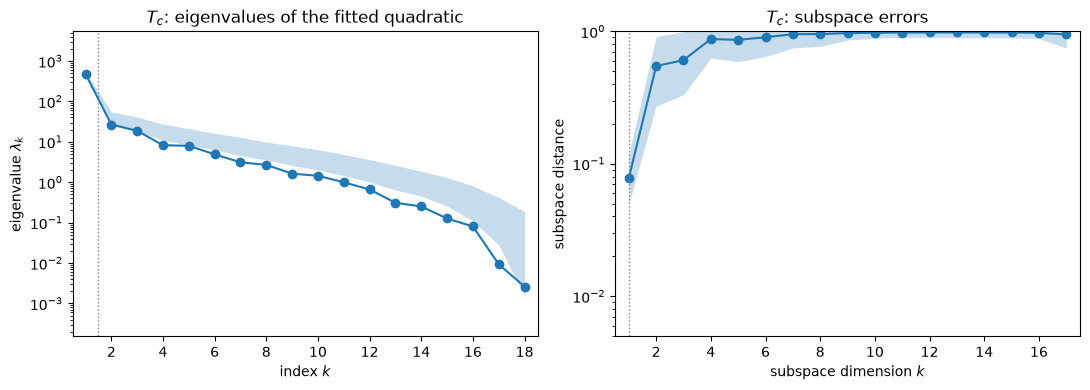

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ac.plotting.plot_eigenvalues(sub_T, ax=axs[0])
ac.plotting.plot_subspace_errors(sub_T, ax=axs[1])
axs[0].set_title('$T_c$: eigenvalues of the fitted quadratic')
axs[1].set_title('$T_c$: subspace errors')
fig.tight_layout()
plt.close(fig)
fig

After the first eigenvalue the spectrum falls by a factor of about 18 (17.7) and then decays slowly. The subspace error is 0.078 for $k$ = 1 and 0.547 for $k$ = 2, so only the first direction is well determined from these runs.

w1: c3 -0.874, c0 -0.268, c1 +0.267, alpha_anom -0.208, u_n +0.149
w2: alpha_anom -0.721, c0 -0.565, c3 +0.344, c2 +0.122, dz_anom -0.092


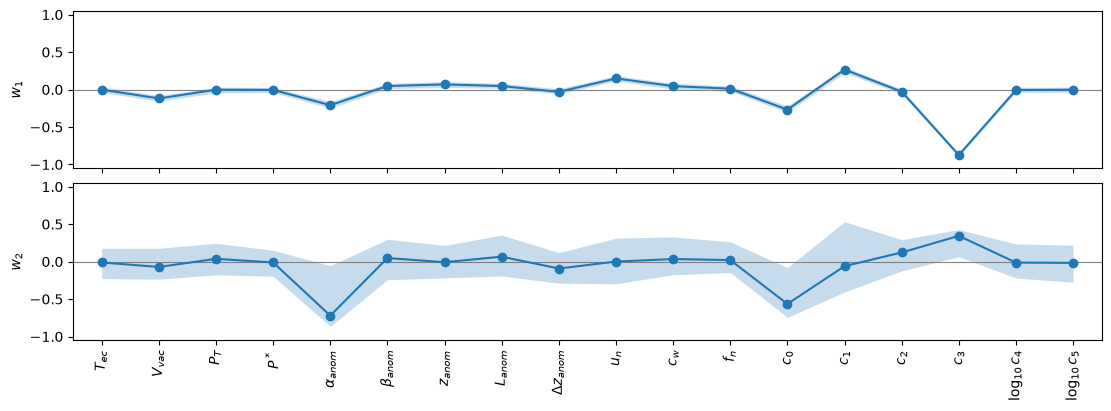

In [10]:
fig, axs = ac.plotting.plot_eigenvectors(sub_T, indices=[0, 1], labels=LABELS, interval='percentile',
                                         figsize=(11, 4))
for ax in axs:
    ax.tick_params(axis='x', labelrotation=90)
w = sub_T.W
for j in range(2):
    top = np.argsort(-np.abs(w[:, j]))[:5]
    print(f'w{j + 1}:', ', '.join(f'{NAMES[i]} {w[i, j]:+.3f}' for i in top))
fig

$w_1$ is dominated by $c_3$ (−0.874), then $c_0$ (−0.268) and $c_1$ (+0.267), all plume parameters: a wider main beam (larger $c_3$), more current in the scattered population (larger $c_0$) and a wider scattered beam relative to the main beam (smaller $c_1$) all raise the divergence angle and lower $T_c = T\cos\phi_d$. The thruster enters through $\alpha_{anom}$ (−0.208) and $u_n$ (+0.149), which change the uncorrected thrust. $w_2$ ($\alpha_{anom}$ −0.721, $c_0$ −0.565, $c_3$ +0.344) has wide bootstrap bands, as expected with $\lambda_2/\lambda_3$ = 1.4.

steady runs: Tc 40.9 to 99.4 mN; oscillating runs: 20.9 to 91.5 mN


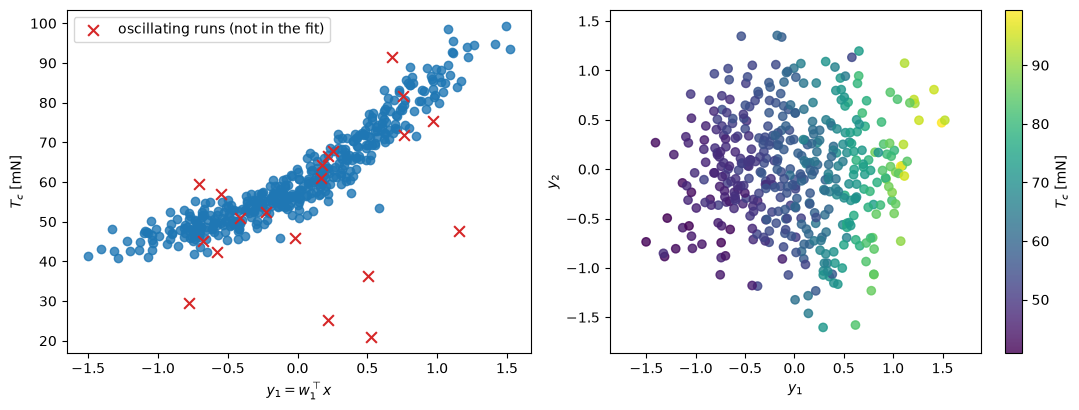

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
ac.plotting.plot_sufficient_summary(sub_T, X=X[st], f=Tc[st], dims=1, qoi_label='$T_c$ [mN]', ax=axs[0])
ac.plotting.plot_sufficient_summary(sub_T, X=X[st], f=Tc[st], dims=2, qoi_label='$T_c$ [mN]', ax=axs[1])
y = Xn @ sub_T.W[:, :1]
axs[0].scatter(y[osc, 0], Tc[osc], marker='x', s=60, color='C3', label='oscillating runs (not in the fit)')
print(f'steady runs: Tc {Tc[st].min():.1f} to {Tc[st].max():.1f} mN; oscillating runs: {Tc[osc].min():.1f} to {Tc[osc].max():.1f} mN')
axs[0].legend()
fig.tight_layout()
plt.close(fig)
fig

For the steady runs $T_c$ rises along $y_1$ from 40.9 to 99.4 mN on a smooth, convex curve, with a band of a few mN around it. The oscillating runs (red crosses, not used in the fit) scatter on both sides of the curve, from 20.9 to 91.5 mN, several far below it: their 500 µs averages, not the inputs, put them there. Colour in the two-variable plot changes mainly with $y_1$, as the eigenvalues say.

### Results: discharge current $I_D$

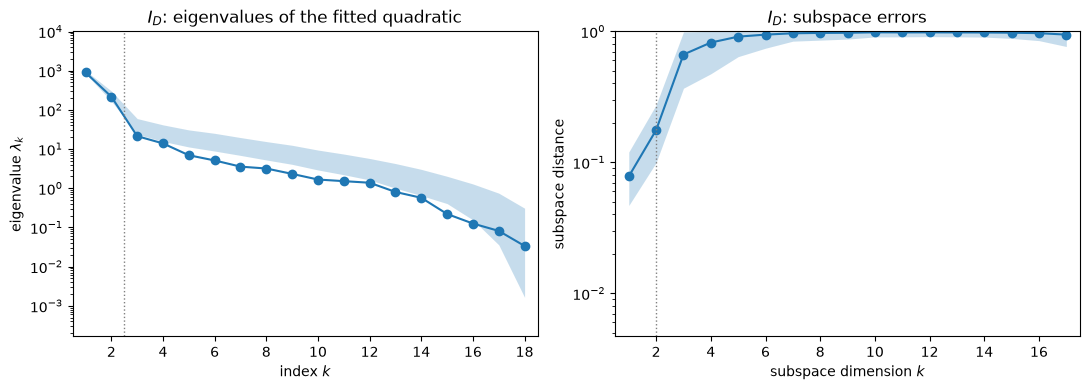

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ac.plotting.plot_eigenvalues(sub_I, ax=axs[0])
ac.plotting.plot_subspace_errors(sub_I, ax=axs[1])
axs[0].set_title('$I_D$: eigenvalues of the fitted quadratic')
axs[1].set_title('$I_D$: subspace errors')
fig.tight_layout()
plt.close(fig)
fig

Two eigenvalues stand out: $\lambda_1/\lambda_2$ = 4.1, then a factor of about 10 (10.2) to $\lambda_3$. The subspace errors are 0.078, 0.176 and 0.665 for $k$ = 1, 2, 3, so both leading directions are well determined.

w1: alpha_anom +0.922, beta_anom -0.346, L_anom -0.140, c_w +0.089, Vvac -0.028
w2: beta_anom -0.900, alpha_anom -0.368, L_anom -0.206, PT +0.059, log10_c5 -0.053


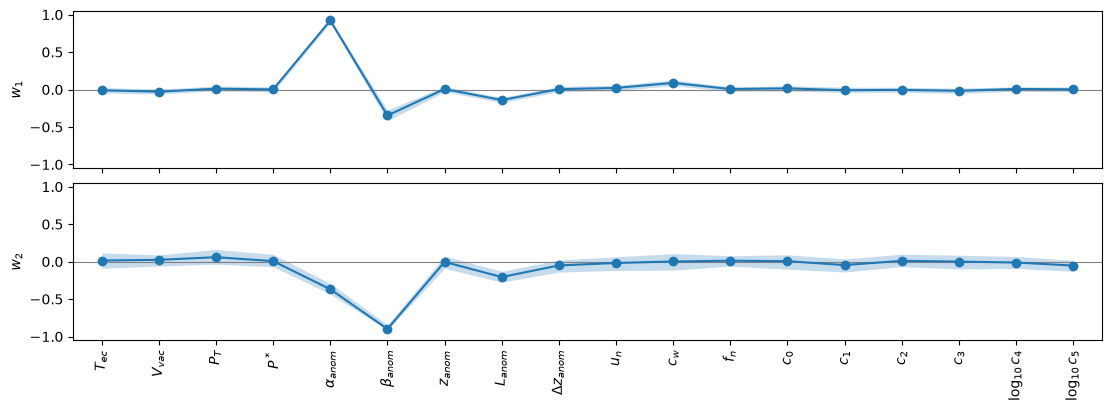

In [13]:
fig, axs = ac.plotting.plot_eigenvectors(sub_I, indices=[0, 1], labels=LABELS, interval='percentile',
                                         figsize=(11, 4))
for ax in axs:
    ax.tick_params(axis='x', labelrotation=90)
w = sub_I.W
for j in range(2):
    top = np.argsort(-np.abs(w[:, j]))[:5]
    print(f'w{j + 1}:', ', '.join(f'{NAMES[i]} {w[i, j]:+.3f}' for i in top))
fig

$w_1$ is mostly $\alpha_{anom}$ (+0.922) with $\beta_{anom}$ (−0.346); $w_2$ is mostly $\beta_{anom}$ (−0.900) with $\alpha_{anom}$ (−0.368). Together they span the transport scale and the barrier depth of Eq. (3), with $L_{anom}$ next (−0.140, −0.206); no other input reaches 0.1 in either vector. The discharge current grows with the overall anomalous transport and falls with a deeper barrier, which lowers the electron current where the barrier sits. The cathode and plume parameters do not enter (the plume is downstream of $I_D$).

steady runs: ID 4.7 to 69.2 A; oscillating runs: 2.9 to 27.8 A


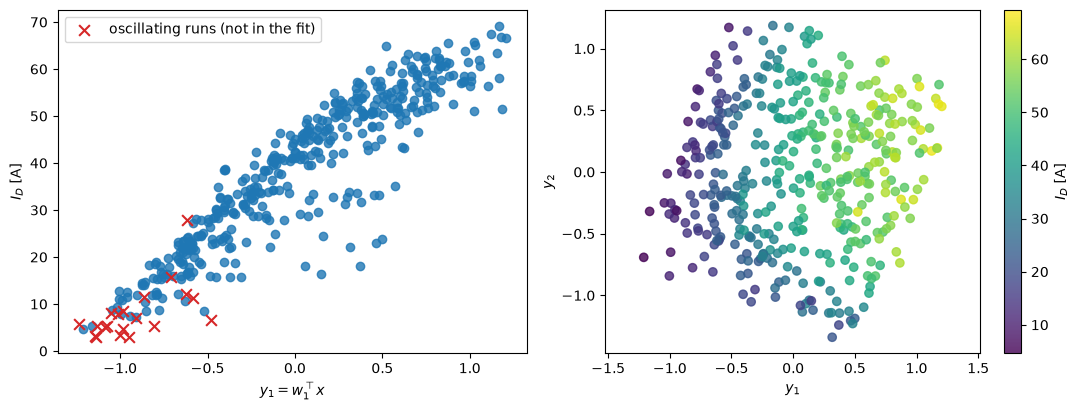

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
ac.plotting.plot_sufficient_summary(sub_I, X=X[st], f=ID[st], dims=1, qoi_label='$I_D$ [A]', ax=axs[0])
ac.plotting.plot_sufficient_summary(sub_I, X=X[st], f=ID[st], dims=2, qoi_label='$I_D$ [A]', ax=axs[1])
y = Xn @ sub_I.W[:, :1]
axs[0].scatter(y[osc, 0], ID[osc], marker='x', s=60, color='C3', label='oscillating runs (not in the fit)')
print(f'steady runs: ID {ID[st].min():.1f} to {ID[st].max():.1f} A; oscillating runs: {ID[osc].min():.1f} to {ID[osc].max():.1f} A')
axs[0].legend()
fig.tight_layout()
plt.close(fig)
fig

Against $y_1$ alone, the steady runs' $I_D$ (4.7 to 69.2 A) follows a nearly linear trend, with a lower branch of runs well below it for $y_1 > -0.5$; in the $(y_1, y_2)$ plane the colour changes smoothly in both directions, so the second variable (mostly the barrier depth) accounts for that branch. The oscillating runs (red crosses) all sit at the low-current end, 2.9 to 27.8 A, nearest the 4.5 A measured at this condition: the low-transport discharges are the ones that develop a breathing-mode oscillation. They lie close to the trend, so averaging noise matters less for $I_D$ than for $T_c$.

### Surrogates on the active variables

Cubic polynomials in one and two active variables, with leave-one-out $R^2$ (the directions are kept fixed). Main rows: fitted to the 420 steady runs with the steady-run directions. Sensitivity rows: fitted to all 440 runs with the all-runs directions.

Tc: cubic in 1 active variable(s): leave-one-out R^2 = 0.921 (steady runs), 0.824 (all runs)
  Tc: of the 5 largest leave-one-out residuals of the all-runs 1-variable cubic, 4 are oscillating runs
Tc: cubic in 2 active variable(s): leave-one-out R^2 = 0.940 (steady runs), 0.857 (all runs)
ID: cubic in 1 active variable(s): leave-one-out R^2 = 0.844 (steady runs), 0.855 (all runs)
  ID: of the 5 largest leave-one-out residuals of the all-runs 1-variable cubic, 0 are oscillating runs
ID: cubic in 2 active variable(s): leave-one-out R^2 = 0.959 (steady runs), 0.963 (all runs)


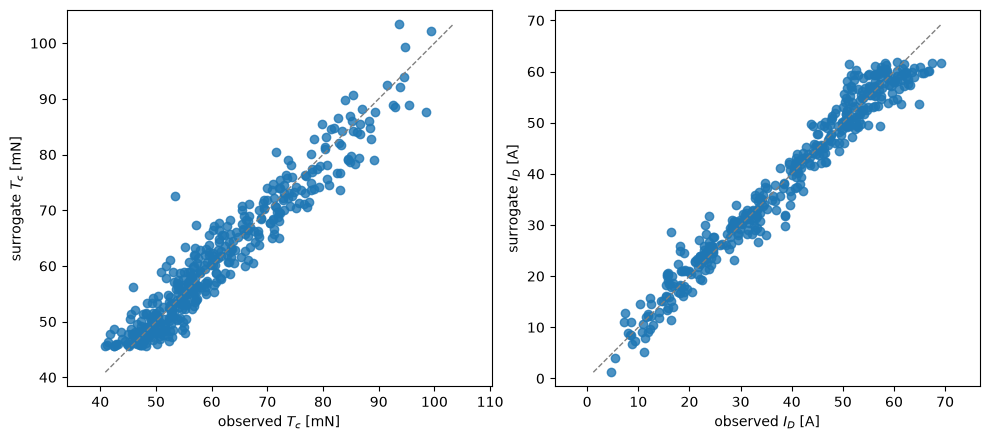

In [15]:
surr = {}
for qoi, sub, sub_all, f in [('Tc', sub_T, sub_T_all, Tc), ('ID', sub_I, sub_I_all, ID)]:
    for n in (1, 2):
        s = ac.fit_surrogate(X=X[st], f=f[st], space=space, subspace=ac.with_dimension(sub, n), kind='poly', degree=3)
        s_all = ac.fit_surrogate(X=X, f=f, space=space, subspace=ac.with_dimension(sub_all, n), kind='poly', degree=3)
        surr[qoi, n] = s
        print(f'{qoi}: cubic in {n} active variable(s): leave-one-out R^2 = {s.loo_r_squared:.3f} (steady runs), '
              f'{s_all.loo_r_squared:.3f} (all runs)')
        if n == 1:
            big = np.argsort(-np.abs(s_all.loo_residuals))[:5]
            print(f'  {qoi}: of the 5 largest leave-one-out residuals of the all-runs 1-variable cubic, {np.sum(osc[big])} are oscillating runs')
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
ac.plotting.plot_surrogate_fit(surr['Tc', 1], X=X[st], f=Tc[st], qoi_label='$T_c$ [mN]', ax=axs[0])
ac.plotting.plot_surrogate_fit(surr['ID', 2], X=X[st], f=ID[st], qoi_label='$I_D$ [A]', ax=axs[1])
fig.tight_layout()
plt.close(fig)
fig

For $T_c$, a cubic in one active variable fitted to the steady runs has leave-one-out $R^2$ 0.921, close to the full 190-term quadratic's 0.939, and a second variable adds little (0.940). With all runs the same cubic reaches only 0.824, and four of its five largest leave-one-out residuals are oscillating runs. For $I_D$ the cubic in two active variables reaches 0.959 against 0.844 for one (all runs: 0.963 and 0.855), which supports $n$ = 2; none of the all-runs cubic's five largest residuals is an oscillating run, because the misfit is the second direction, not noise. The plots show the one-variable $T_c$ and two-variable $I_D$ surrogates on the steady runs.

### Comparison with the paper

The paper reports no active subspace. Its global sensitivity analysis (Sec. III E, Fig. 18a, p. 21) gives Sobol' total-effect indices over the SPT-100 prior for five QoIs, from 5000 prior samples, as bar charts only; the values below were read off the figure (bar tops measured on a 300 dpi rendering of the page, about ±0.01; bars below about 0.02 are not listed). The notebook's counterpart is the share of the activity score $a_i = \sum_{j\le 2}\lambda_j w_{ij}^2$ from the two-dimensional QPHD subspace of each QoI. Activity shares sum to 1 and total-effect indices need not (they count interactions once per input), so only the rankings are compared. Shares are given for the steady runs (main) and all runs (sensitivity). The paper's $j_{ion}$ is the peak current density; here its logarithm is used, which has the same ranking of inputs only approximately.

In [16]:
qois = {'Vcc': col['Vcc'][ok], 'ID': ID, 'Tc': Tc, 'u_exit': col['u_exit'][ok], 'log10_j_peak': np.log10(col['j_peak'][ok])}
# Fig. 18a (SPT-100, prior), total-effect indices read off the bars, about +-0.01
FIG18A = {'Vcc': {'Vvac': 1.01},
          'ID': {'alpha_anom': 0.76, 'beta_anom': 0.21, 'L_anom': 0.06},
          'Tc': {'c3': 0.68, 'c0': 0.11, 'alpha_anom': 0.11, 'c1': 0.10, 'u_n': 0.03, 'Vvac': 0.02, 'beta_anom': 0.02},
          'u_exit': {'z_anom': 0.93, 'beta_anom': 0.52, 'L_anom': 0.09, 'alpha_anom': 0.07, 'dz_anom': 0.03, 'Vvac': 0.02},
          'log10_j_peak': {'c3': 0.87, 'log10_c4': 0.30, 'c0': 0.14, 'c1': 0.04, 'c2': 0.03}}
share = {}
for q, f in qois.items():
    for label, rows in [('steady', st), ('all', all_rows)]:
        s = ac.active_subspace(space=space, X=X[rows], f=f[rows], estimator='qphd', n=2)
        a = ac.activity_scores(s, n=2)
        share[q, label] = a / a.sum()
    cannot = list(range(4, m)) if q == 'Vcc' else (list(range(12, m)) if q in ('ID', 'u_exit') else [])
    floor = f'; largest share of an input that cannot affect it: {share[q, "steady"][cannot].max():.3f}' if cannot else ''
    pt = f'; shares of PT, Pstar: {share[q, "steady"][2]:.1e}, {share[q, "steady"][3]:.1e} (steady), {share[q, "all"][2]:.1e}, {share[q, "all"][3]:.1e} (all)'
    print(f'{q}: quadratic R^2 (steady runs) {r2_quadratic(f, st)[0]:.3f}{floor}{pt}')
    print(f'  {"input":>11}  {"Fig. 18a":>8}  {"share, steady":>13} (rank)  {"share, all":>10} (rank)')
    rank = {lab: np.argsort(np.argsort(-share[q, lab])) + 1 for lab in ('steady', 'all')}
    shown = list(FIG18A[q]) + [NAMES[i] for i in np.argsort(-share[q, 'steady'])[:4] if NAMES[i] not in FIG18A[q]]
    for name in shown:
        i = NAMES.index(name)
        paper = f'{FIG18A[q][name]:8.2f}' if name in FIG18A[q] else f'{"< 0.02":>8}'
        print(f'  {name:>11}  {paper}  {share[q, "steady"][i]:13.3f} ({rank["steady"][i]:2d})  '
              f'{share[q, "all"][i]:10.3f} ({rank["all"][i]:2d})')

Vcc: quadratic R^2 (steady runs) 1.000; largest share of an input that cannot affect it: 0.000; shares of PT, Pstar: 2.7e-04, 3.9e-05 (steady), 2.6e-04, 3.7e-05 (all)
        input  Fig. 18a  share, steady (rank)  share, all (rank)
         Vvac      1.01          1.000 ( 1)       1.000 ( 1)
           PT    < 0.02          0.000 ( 2)       0.000 ( 2)
        Pstar    < 0.02          0.000 ( 3)       0.000 ( 4)
          Tec    < 0.02          0.000 ( 4)       0.000 ( 3)
ID: quadratic R^2 (steady runs) 0.983; largest share of an input that cannot affect it: 0.001; shares of PT, Pstar: 7.9e-04, 1.1e-05 (steady), 5.0e-04, 6.7e-05 (all)
        input  Fig. 18a  share, steady (rank)  share, all (rank)
   alpha_anom      0.76          0.712 ( 1)       0.723 ( 1)
    beta_anom      0.21          0.254 ( 2)       0.242 ( 2)
       L_anom      0.06          0.024 ( 3)       0.023 ( 3)
          c_w    < 0.02          0.006 ( 4)       0.007 ( 4)
Tc: quadratic R^2 (steady runs) 0.984; shares of 

u_exit: quadratic R^2 (steady runs) 0.867; largest share of an input that cannot affect it: 0.013; shares of PT, Pstar: 3.9e-03, 1.5e-04 (steady), 4.0e-03, 8.0e-05 (all)
        input  Fig. 18a  share, steady (rank)  share, all (rank)
       z_anom      0.93          0.630 ( 1)       0.629 ( 1)
    beta_anom      0.52          0.302 ( 2)       0.298 ( 2)
       L_anom      0.09          0.007 ( 7)       0.012 ( 4)
   alpha_anom      0.07          0.009 ( 5)       0.005 ( 8)
      dz_anom      0.03          0.012 ( 4)       0.012 ( 3)
         Vvac      0.02          0.008 ( 6)       0.008 ( 7)
           c1    < 0.02          0.013 ( 3)       0.009 ( 5)
log10_j_peak: quadratic R^2 (steady runs) 0.962; shares of PT, Pstar: 3.9e-04, 4.9e-04 (steady), 5.0e-04, 6.2e-04 (all)
        input  Fig. 18a  share, steady (rank)  share, all (rank)
           c3      0.87          0.626 ( 1)       0.631 ( 1)
     log10_c4      0.30          0.315 ( 2)       0.311 ( 2)
           c0      0.14        

| quantity | paper (Sobol' total indices over the prior, Fig. 18a, read off) | this notebook (QPHD activity shares, $n$ = 2, steady runs; all runs in brackets) |
|---|---|---|
| $V_{cc}$ | $V_{vac}$ 1.01 | $V_{vac}$ 1.000 |
| $I_D$ | $\alpha_{anom}$ 0.76 > $\beta_{anom}$ 0.21 > $L_{anom}$ 0.06 | $\alpha_{anom}$ 0.712 > $\beta_{anom}$ 0.254 > $L_{anom}$ 0.024 (same order) |
| $T_c$ | $c_3$ 0.68 > $c_0$ 0.11 ≈ $\alpha_{anom}$ 0.11 > $c_1$ 0.10 > $u_n$ 0.03 | $c_3$ 0.730 > $c_0$ 0.085 > $\alpha_{anom}$ 0.069 ≈ $c_1$ 0.068 > $u_n$ 0.021 (all runs: $\alpha_{anom}$ 0.017, 5th) |
| exit-plane ion velocity | $z_{anom}$ 0.93 > $\beta_{anom}$ 0.52 > $L_{anom}$ 0.09 > $\alpha_{anom}$ 0.07 | $z_{anom}$ 0.630 > $\beta_{anom}$ 0.302; the rest ≤ 0.013 |
| peak plume current density | $c_3$ 0.87 > $c_4$ 0.30 > $c_0$ 0.14 > $c_1$ 0.04 | $\log_{10}j$: $c_3$ 0.626 > $\log_{10}c_4$ 0.315 > $c_0$ 0.029 > $c_1$ 0.015 (same order) |
| neutral ingestion $f_n$ | below 0.02 for every QoI | not among the listed inputs for any QoI |
| active subspace | not reported | $T_c$: $n$ = 1, $\lambda_1/\lambda_2\approx$ 18 (17.7; all runs 10.7); $I_D$: $n$ = 2, $\lambda_2/\lambda_3\approx$ 10 (10.2; all runs 12.8) |

On the steady runs, the leading inputs rank as in the paper's Fig. 18a for every QoI: all listed inputs for $V_{cc}$ and $I_D$, the first four for the current density (the paper's fifth, $c_2$ at 0.03, is sixth here, as expected at this $P_B$), the first five for $T_c$ (up to the ties below), and the first two for the exit ion velocity. For $T_c$ the paper's $c_0$ and $\alpha_{anom}$ are tied (0.11 each) and here $\alpha_{anom}$ and $c_1$ are tied (0.069 and 0.068), so the order of the second to fourth inputs is not resolved by either analysis. Including the 20 oscillating runs moves $\alpha_{anom}$ to fifth for thrust: its share falls from 0.069 to 0.017 and $c_1$'s rises from 0.068 to 0.105. Those runs all lie at low $\alpha_{anom}$ (at most 0.261), and their thrust carries averaging errors of up to about 10 %, which the quadratic fits as if they were model variation. For the exit ion velocity the paper's text names $\alpha_{anom}$ among the three dominant inputs, but its own bar (0.07) is below $L_{anom}$'s (0.09); here both (0.009 and 0.007) are at the noise level of the quadratic fit (the largest share of a plume input, which cannot affect the ion velocity, is 0.013). The remaining differences are in the size of the secondary shares (for example $c_0$ 0.14 against 0.029 for the current density), which activity shares and total-effect indices need not agree on; the fixed operating condition (the paper samples its operating conditions; at which conditions Fig. 18 was computed is not stated) may also contribute.

In [17]:
print(f'notebook run time: {time.perf_counter() - t_start:.1f} s')

notebook run time: 50.9 s


### References

[1] T. A. Marks, J. D. Eckels, G. E. Mora and A. A. Gorodetsky. Uncertainty quantification of a multi-component Hall thruster model at varying facility pressures. *Journal of Applied Physics* 138(15):153305, 2025. [doi:10.1063/5.0283796](https://doi.org/10.1063/5.0283796). (Erratum: *J. Appl. Phys.* 139(3):039901, 2026, [doi:10.1063/5.0314947](https://doi.org/10.1063/5.0314947), which corrects Eq. (6) only; the corrected form is the one used here. This notebook was written from the authors' manuscript dated 21 October 2025.)

[2] P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*. SIAM, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)

[3] T. Marks, P. Schedler and B. Jorns. HallThruster.jl: a Julia package for 1D Hall thruster discharge simulation. *Journal of Open Source Software* 8(86):4672, 2023. [doi:10.21105/joss.04672](https://doi.org/10.21105/joss.04672)

[4] B. A. Jorns and M. P. Byrne. Model for the dependence of cathode voltage in a Hall thruster on facility pressure. *Plasma Sources Science and Technology* 30(1):015012, 2021. [doi:10.1088/1361-6595/abd3b6](https://doi.org/10.1088/1361-6595/abd3b6)

[5] J. D. Eckels, T. A. Marks, M. G. Allen, B. A. Jorns and A. A. Gorodetsky. Hall thruster model improvement by multidisciplinary uncertainty quantification. *Journal of Electric Propulsion* 3:19, 2024. [doi:10.1007/s44205-024-00079-w](https://doi.org/10.1007/s44205-024-00079-w)

[6] K. D. Diamant, R. Liang and R. L. Corey. The effect of background pressure on SPT-100 Hall thruster performance. 50th AIAA/ASME/SAE/ASEE Joint Propulsion Conference, AIAA 2014-3710, 2014. [doi:10.2514/6.2014-3710](https://doi.org/10.2514/6.2014-3710)

[7] K.-C. Li. On principal Hessian directions for data visualization and dimension reduction: another application of Stein's lemma. *Journal of the American Statistical Association* 87(420):1025–1039, 1992. [doi:10.1080/01621459.1992.10476258](https://doi.org/10.1080/01621459.1992.10476258)

### Acknowledgments

The paper's work was funded by NASA through the Joint Advanced Propulsion Institute (JANUS), a NASA Space Technology Research Institute, grant 80NSSC21K1118, and a NASA Space Technology Graduate Research Opportunity grant 80NSSC23K1181, with computing from Advanced Research Computing at the University of Michigan.